# 06 · Evaluate the internal 180-image holdout

Notebook 03 pooled the 18 classes in `v20261026_2355546.zip`, removed exact duplicates, and reserved 10 random images per class with seed 42. This notebook evaluates saved EfficientNet-B2, DINOv3, and SigLIP2 heads on that **untouched internal holdout**. It loads images directly from the packaged ZIP and verifies the four split manifests before inference.

This holdout is from the same source collection as training. Report it as an internal holdout, not as independent real-world performance. Avoid using its results to tune hyperparameters or select a model repeatedly.


## 1. Set up Colab and locate saved runs

Run notebook 03 first and keep its four CSV manifests plus model artifacts in Drive. DINOv3 needs approved model access and `HF_TOKEN` in Colab Secrets. Encoders run one at a time to fit a free Colab GPU.


In [1]:
import subprocess
import sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                       'transformers>=4.57,<5', 'scikit-learn>=1.5,<2'])


0

In [2]:
from pathlib import Path
from io import BytesIO
from zipfile import ZipFile
import gc
import hashlib
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
import torch
from torch import nn
from torchvision.models import EfficientNet_B2_Weights, efficientnet_b2
from transformers import AutoImageProcessor, AutoModel, AutoProcessor
from huggingface_hub import get_token

SEED = 42
DATASET_VERSION = 'v20261026_2355546'
MODEL_NAMES = ('efficientnet_b2', 'dinov3', 'siglip2')
BATCH_SIZE = 8  # Reduce to 4 if Colab runs out of GPU memory.
SAVE_TO_DRIVE = True
IN_COLAB = 'google.colab' in sys.modules
if SAVE_TO_DRIVE:
    if not IN_COLAB:
        raise RuntimeError('Use Colab for Drive storage, or set SAVE_TO_DRIVE=False locally.')
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_ROOT = Path('/content/drive/MyDrive')
    ARCHIVE_PATH = DRIVE_ROOT / 'AI/meta-global-hackaton/data' / f'plant_export_{DATASET_VERSION}_holdout10_seed{SEED}.zip'
    RUNS_DIR = DRIVE_ROOT / 'AI/meta-global-hackaton/runs' / f'plant_export_{DATASET_VERSION}_holdout10_seed{SEED}'
else:
    ARCHIVE_PATH = Path('./data/processed') / f'plant_export_{DATASET_VERSION}_holdout10_seed{SEED}.zip'
    RUNS_DIR = Path('./data/processed/runs') / f'plant_export_{DATASET_VERSION}_holdout10_seed{SEED}'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
HF_TOKEN = os.environ.get('HF_TOKEN')
if IN_COLAB and not HF_TOKEN:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get('HF_TOKEN')
    except Exception:
        HF_TOKEN = None
if not HF_TOKEN:
    HF_TOKEN = get_token()
if not ARCHIVE_PATH.is_file():
    raise FileNotFoundError(f'Dataset ZIP missing: {ARCHIVE_PATH}')
if not RUNS_DIR.is_dir():
    raise FileNotFoundError(f'Run notebook 03 first; missing: {RUNS_DIR}')
print('Device:', DEVICE, '| Runs:', RUNS_DIR)


Mounted at /content/drive
Device: cpu | Runs: /content/drive/MyDrive/AI/meta-global-hackaton/runs/plant_export_v20261026_2355546_holdout10_seed42


## 2. Verify the holdout and split fingerprint

The holdout must have exactly 180 unique hashes, 10 in each class, and no exact hash overlap with train, validation, or test. Every held-out ZIP member is checked against its recorded SHA-256 before inference. The split fingerprint must match every saved model run.


In [3]:
def read_json(path: Path) -> dict:
    return json.loads(path.read_text(encoding='utf-8'))


frames = {}
for name in ('train', 'val', 'test', 'external_test'):
    path = RUNS_DIR / f'{name}.csv'
    if not path.is_file():
        raise FileNotFoundError(f'Missing {path}; rerun notebook 03')
    frame = pd.read_csv(path)
    required = {'image_id', 'zip_member', 'class_name', 'target', 'sha256', 'split'}
    if not required <= set(frame.columns) or not frame.split.eq(name).all():
        raise ValueError(f'Invalid {name} manifest: {path}')
    frames[name] = frame
photos = frames['external_test'].sort_values('image_id').reset_index(drop=True)
if len(photos) != 180 or photos.class_name.nunique() != 18:
    raise ValueError('Holdout must contain 180 images across 18 classes')
if not photos.groupby('class_name').size().eq(10).all():
    raise ValueError('Holdout needs exactly 10 images per class')
all_rows = pd.concat(frames.values(), ignore_index=True)
if all_rows.sha256.duplicated().any() or all_rows.image_id.duplicated().any():
    raise ValueError('Image or exact content overlaps across new splits')
identity = sorted((row.sha256, row.split, row.class_name)
                  for row in all_rows.itertuples(index=False))
DATASET_FINGERPRINT = hashlib.sha256(
    json.dumps(identity, separators=(',', ':')).encode()).hexdigest()[:16]
with ZipFile(ARCHIVE_PATH) as archive:
    for row in photos.itertuples(index=False):
        image_bytes = archive.read(row.zip_member)
        if hashlib.sha256(image_bytes).hexdigest() != row.sha256:
            raise ValueError(f'Holdout image changed: {row.zip_member}')
        with Image.open(BytesIO(image_bytes)) as image:
            image.verify()
EXPECTED_CLASSES = tuple(photos[['target', 'class_name']].drop_duplicates()
                         .sort_values('target').class_name)
if tuple(range(18)) != tuple(sorted(photos.target.unique())):
    raise ValueError('Expected contiguous model target indices 0–17')
print('Verified internal holdout:', len(photos), 'images; fingerprint:', DATASET_FINGERPRINT)
display(photos.groupby('class_name').size().rename('holdout_images').to_frame())


Verified internal holdout: 180 images; fingerprint: a36fa81fded18e69


,holdout_images
class_name,
aglaonema,10
aloe vera,10
chamaedorea elegans,10
chlorophytum comosum,10
chrysanthemum,10
crassula ovata,10
cyclamen,10
dieffenbachia,10
epipremnum aureum,10


In [4]:
runs = []
for name in MODEL_NAMES:
    folder = RUNS_DIR / name
    required_files = ('config.json', 'dataset_metadata.json', 'class_mapping.json',
                      'metrics.json', 'best_head.pt')
    if not folder.is_dir():
        print('No saved run; skipping:', name)
        continue
    if not all((folder / filename).is_file() for filename in required_files):
        raise FileNotFoundError(f'Incomplete run: {folder}')
    training = read_json(folder / 'config.json')['training']
    dataset = read_json(folder / 'dataset_metadata.json')
    mapping = read_json(folder / 'class_mapping.json')
    metrics = read_json(folder / 'metrics.json')
    if training['model_name'] != name or dataset['version_tag'] != DATASET_VERSION:
        raise ValueError(f'Run identity mismatch: {folder}')
    if dataset['dataset_fingerprint'] != DATASET_FINGERPRINT:
        raise ValueError(f'Run was trained with different split manifests: {folder}')
    if tuple(mapping['index_to_class']) != EXPECTED_CLASSES:
        raise ValueError(f'Class order mismatch: {folder}')
    runs.append({'name': name, 'dir': folder, 'training': training, 'metrics': metrics})
if not runs:
    raise FileNotFoundError('No trained runs found; finish notebook 03 first')
print('Comparable runs:', [run['name'] for run in runs])


Comparable runs: ['efficientnet_b2', 'dinov3', 'siglip2']


## 3. Run each saved encoder and classifier head

Use the same encoder IDs and image processors as notebook 03. The holdout labels are used only to score predictions after inference. Predictions and class reports are saved beside the new runs in Drive.


In [5]:
def make_encoder(training: dict):
    name = training['model_name']
    if name == 'efficientnet_b2':
        weights = EfficientNet_B2_Weights.IMAGENET1K_V1
        encoder = efficientnet_b2(weights=weights)
        encoder.classifier = nn.Identity()
        return encoder.to(DEVICE).eval(), weights.transforms()
    encoder_id = training['hf_dinov3_id'] if name == 'dinov3' else training['hf_siglip2_id']
    token = HF_TOKEN if name == 'dinov3' else None
    if name == 'dinov3' and not token:
        raise RuntimeError('DINOv3 requires approved access and HF_TOKEN in Colab Secrets')
    processor = (AutoImageProcessor if name == 'dinov3' else AutoProcessor).from_pretrained(
        encoder_id, token=token)
    encoder = AutoModel.from_pretrained(encoder_id, token=token).to(DEVICE).eval()
    return encoder, processor


def embedding_tensor(output):
    if torch.is_tensor(output):
        return output
    for attribute in ('image_embeds', 'pooler_output'):
        value = getattr(output, attribute, None)
        if torch.is_tensor(value):
            return value
    hidden = getattr(output, 'last_hidden_state', None)
    if torch.is_tensor(hidden):
        return hidden[:, 0]
    raise TypeError(f'No image embedding in {type(output).__name__}')


def load_head(run: dict) -> nn.Module:
    state = torch.load(run['dir'] / 'best_head.pt', map_location='cpu', weights_only=True)
    width = state['0.weight'].numel()
    head = nn.Sequential(nn.LayerNorm(width), nn.Dropout(0.2),
                         nn.Linear(width, len(EXPECTED_CLASSES)))
    head.load_state_dict(state, strict=True)
    return head.to(DEVICE).eval()


def predict_run(run: dict) -> pd.DataFrame:
    encoder, processor = make_encoder(run['training'])
    head = load_head(run)
    rows = []
    with ZipFile(ARCHIVE_PATH) as archive, torch.inference_mode():
        for start in range(0, len(photos), BATCH_SIZE):
            batch = photos.iloc[start:start + BATCH_SIZE]
            images = []
            for row in batch.itertuples(index=False):
                with Image.open(BytesIO(archive.read(row.zip_member))) as image:
                    images.append(image.convert('RGB'))
            if run['name'] == 'efficientnet_b2':
                inputs = torch.stack([processor(image) for image in images]).to(DEVICE)
                features = encoder(inputs)
            else:
                inputs = processor(images=images, return_tensors='pt')
                inputs = {key: value.to(DEVICE) if torch.is_tensor(value) else value
                          for key, value in inputs.items()}
                output = (encoder.get_image_features(**inputs) if run['name'] == 'siglip2'
                          else encoder(**inputs, return_dict=True))
                features = embedding_tensor(output)
            if features.ndim != 2 or features.shape[1] != head[0].normalized_shape[0]:
                raise ValueError(f'Encoder/head feature shape mismatch: {run["name"]}')
            scores, indices = head(features.float()).softmax(dim=1).topk(3)
            for source, top_scores, top_indices in zip(batch.to_dict('records'),
                                                        scores.cpu().tolist(),
                                                        indices.cpu().tolist(), strict=True):
                prediction = dict(source)
                prediction['model_name'] = run['name']
                prediction['predicted_class'] = EXPECTED_CLASSES[top_indices[0]]
                prediction['correct'] = prediction['predicted_class'] == source['class_name']
                for rank, (index, score) in enumerate(zip(top_indices, top_scores, strict=True), 1):
                    prediction[f'top{rank}_class'] = EXPECTED_CLASSES[index]
                    prediction[f'top{rank}_score'] = score
                rows.append(prediction)
            print(f'{run["name"]}: {min(start + BATCH_SIZE, len(photos))}/{len(photos)}', end='\r')
    del encoder, processor, head
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    print()
    return pd.DataFrame(rows)


## 4. Save predictions and compare holdout results

All runs use the same 180 image hashes. Report accuracy and macro F1 with per-class support. The internal test score saved by notebook 03 is a separate diagnostic; the holdout score is still from the same original archive.


In [6]:
OUTPUT_DIR = RUNS_DIR / 'holdout_evaluation' / DATASET_FINGERPRINT
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
summary = []
all_predictions = []
labels = list(EXPECTED_CLASSES)
for run in runs:
    predictions = predict_run(run)
    if len(predictions) != len(photos):
        raise ValueError(f'Incomplete predictions for {run["name"]}')
    predictions.to_csv(OUTPUT_DIR / f'{run["name"]}_predictions.csv', index=False)
    all_predictions.append(predictions)
    report = classification_report(predictions.class_name, predictions.predicted_class,
                                   labels=labels, output_dict=True, zero_division=0)
    per_class = pd.DataFrame([{'class_name': name, **{
        key: report[name][key] for key in ('precision', 'recall', 'f1-score', 'support')
    }} for name in labels])
    per_class.to_csv(OUTPUT_DIR / f'{run["name"]}_per_class.csv', index=False)
    matrix = confusion_matrix(predictions.class_name, predictions.predicted_class,
                              labels=labels)
    pd.DataFrame(matrix, index=labels, columns=labels).to_csv(
        OUTPUT_DIR / f'{run["name"]}_confusion_matrix.csv')
    summary.append({
        'model_name': run['name'],
        'holdout_images': len(predictions),
        'holdout_accuracy': accuracy_score(predictions.class_name, predictions.predicted_class),
        'holdout_macro_f1': f1_score(predictions.class_name, predictions.predicted_class,
                                    labels=labels, average='macro', zero_division=0),
        'internal_test_accuracy': run['metrics']['test']['accuracy'],
        'internal_test_macro_f1': run['metrics']['test']['macro_f1'],
        'split_fingerprint': DATASET_FINGERPRINT,
    })
comparison = pd.DataFrame(summary).sort_values('holdout_macro_f1', ascending=False)
comparison.to_csv(OUTPUT_DIR / 'comparison.csv', index=False)
print('Saved holdout predictions and reports:', OUTPUT_DIR)
display(comparison)


Downloading: "https://download.pytorch.org/models/efficientnet_b2_rwightman-c35c1473.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b2_rwightman-c35c1473.pth


100%|██████████| 35.2M/35.2M [00:00<00:00, 57.3MB/s]


preprocessor_config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/86.4M [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/636 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/253 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.50G [00:00<?, ?B/s]

siglip2: 180/180
Saved holdout predictions and reports: /content/drive/MyDrive/AI/meta-global-hackaton/runs/plant_export_v20261026_2355546_holdout10_seed42/holdout_evaluation/a36fa81fded18e69


,model_name,holdout_images,holdout_accuracy,holdout_macro_f1,internal_test_accuracy,internal_test_macro_f1,split_fingerprint
2,siglip2,180,0.950000,0.949540,0.981982,0.984127,a36fa81fded18e69
1,dinov3,180,0.944444,0.943724,0.972973,0.974632,a36fa81fded18e69
0,efficientnet_b2,180,0.827778,0.821818,0.810811,0.787199,a36fa81fded18e69


## 5. Inspect mistakes

Review wrong predictions by class and inspect the image from the ZIP. The embedded `source_url` is provenance only; it does not establish redistribution rights. Record observations after running the notebook.


,model_name,class_name,predicted_class,top1_score,image_id,source_url
202,dinov3,aglaonema,spathiphyllum,0.448254,v20260925_155046/snapshot/train/0001_aglaonema...,https://upload.wikimedia.org/wikipedia/commons...
196,dinov3,aglaonema,epipremnum aureum,0.441769,v20260925_155046/snapshot/train/0001_aglaonema...,https://upload.wikimedia.org/wikipedia/commons...
201,dinov3,aglaonema,dieffenbachia,0.441525,v20260925_155046/snapshot/train/0001_aglaonema...,https://upload.wikimedia.org/wikipedia/commons...
262,dinov3,dieffenbachia,spathiphyllum,0.488604,v20260925_155046/snapshot/train/0008_dieffenba...,https://upload.wikimedia.org/wikipedia/commons...
303,dinov3,narcissus,hemerocallis,0.390674,v20260925_155046/snapshot/train/0014_narcissus...,https://upload.wikimedia.org/wikipedia/commons...
187,dinov3,narcissus,phalaenopsis,0.334185,v20260925_155046/snapshot/test/0014_narcissus/...,https://upload.wikimedia.org/wikipedia/commons...
315,dinov3,phalaenopsis,chlorophytum comosum,0.367747,v20260925_155046/snapshot/train/0016_phalaenop...,https://upload.wikimedia.org/wikipedia/commons...
356,dinov3,philodendron hederaceum,epipremnum aureum,0.594041,v20260925_155046/snapshot/val/0017_philodendro...,https://upload.wikimedia.org/wikipedia/commons...
325,dinov3,philodendron hederaceum,epipremnum aureum,0.539703,v20260925_155046/snapshot/train/0017_philodend...,https://upload.wikimedia.org/wikipedia/commons...
334,dinov3,spathiphyllum,aglaonema,0.476101,v20260925_155046/snapshot/train/0019_spathiphy...,https://upload.wikimedia.org/wikipedia/commons...


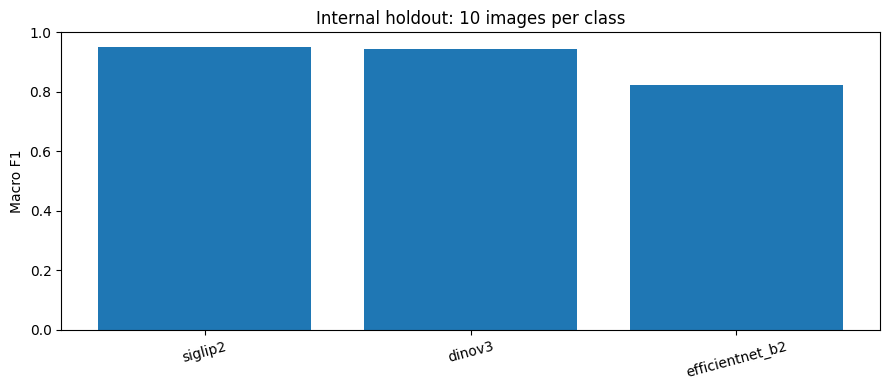

In [7]:
wrong = pd.concat(all_predictions, ignore_index=True)
wrong = wrong[~wrong.correct].sort_values(['model_name', 'class_name', 'top1_score'],
                                          ascending=[True, True, False])
display(wrong[['model_name', 'class_name', 'predicted_class', 'top1_score',
               'image_id', 'source_url']].head(30))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(comparison.model_name, comparison.holdout_macro_f1)
ax.set(ylabel='Macro F1', title='Internal holdout: 10 images per class', ylim=(0, 1))
ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()


## Interpretation

- Record actual findings only after running all cells.
- The 180-image holdout has 10 examples per class, but all images came from the original archive. Do not describe this as an independent external test.
- Review labels and near-duplicates before drawing conclusions. This closed-set identity task does not determine pet toxicity or recognize unknown plants.
